В цьому ноутбуці відбуваєтся тестування рандомних активів на рандомному проміжку часу. Метою є візуальна перевірка коректність роботи бектест алгоритму

In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import numpy as np
import random
import yaml

from app import BacktestDCA
from ploter import ploter

/Users/aleksejkitajskij/Desktop/DCA/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# stocks

In [3]:
df_stocks = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_stocks

,BTC,ETH,SOL,XRP,DOGE,ADA,DOT,LINK,XLM,XMR
Date,,,,,,,,,,
2020-01-01,7200.174316,130.802002,NaN,0.192667,0.002033,0.033458,NaN,1.806640,0.045451,45.753544
2020-01-02,6985.470215,127.410179,NaN,0.188043,0.002009,0.032751,NaN,1.741144,0.044112,45.749470
2020-01-03,7344.884277,134.171707,NaN,0.193521,0.002145,0.034180,NaN,1.809708,0.045234,51.092037
2020-01-04,7410.656738,135.069366,NaN,0.194355,0.002241,0.034595,NaN,1.840133,0.046272,50.536694
2020-01-05,7411.317383,136.276779,NaN,0.195537,0.002419,0.034721,NaN,1.807787,0.045359,54.096893
...,...,...,...,...,...,...,...,...,...,...
2026-10-20,82941.000000,2446.730713,106.422340,1.334452,0.081809,0.223782,1.149771,12.320927,0.181960,600.929504
2026-10-21,84011.968750,2470.766113,106.793655,1.363619,0.081867,0.224979,1.141323,12.484719,0.183488,622.434082
2026-10-22,81311.890625,2386.189209,103.542320,1.307656,0.078676,0.212025,1.111869,11.943166,0.175209,600.638428


In [4]:
sequence_length = 365 * 3

start = random.randint(0, len(df_stocks) - sequence_length)
prices = df_stocks.iloc[start:start + sequence_length]
prices.index.min(), prices.index.max()

(Timestamp('2022-02-17 00:00:00'), Timestamp('2025-02-15 00:00:00'))

In [5]:
token_num = 10

random_token = random.sample(df_stocks.columns.tolist(), token_num)
random_token

['XRP', 'ETH', 'XMR', 'SOL', 'DOT', 'LINK', 'DOGE', 'BTC', 'ADA', 'XLM']

In [6]:
# strategy={"threshold_ma200_sell": 1.5, "threshold_bolinger_sell": 2.0, "threshold_rsi_sell": 70.0, "threshold_ppo_sell": 10.0}
strategy={}

01:04:01 - cmdstanpy - INFO - Chain [1] start processing
01:04:01 - cmdstanpy - INFO - Chain [1] done processing


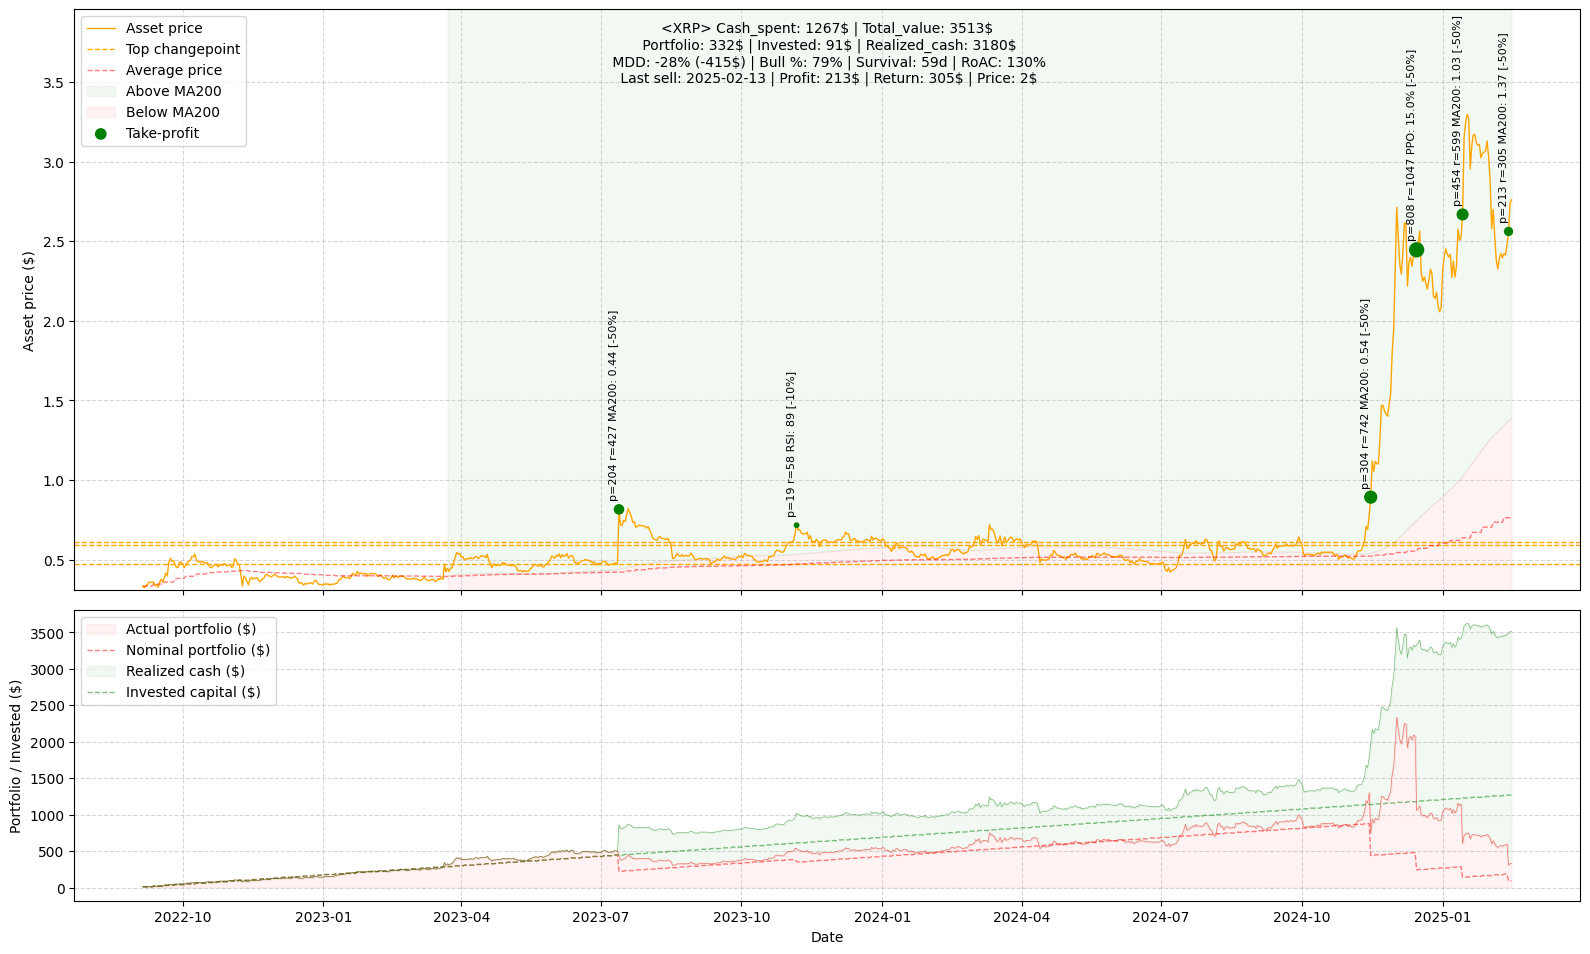

01:04:02 - cmdstanpy - INFO - Chain [1] start processing
01:04:02 - cmdstanpy - INFO - Chain [1] done processing


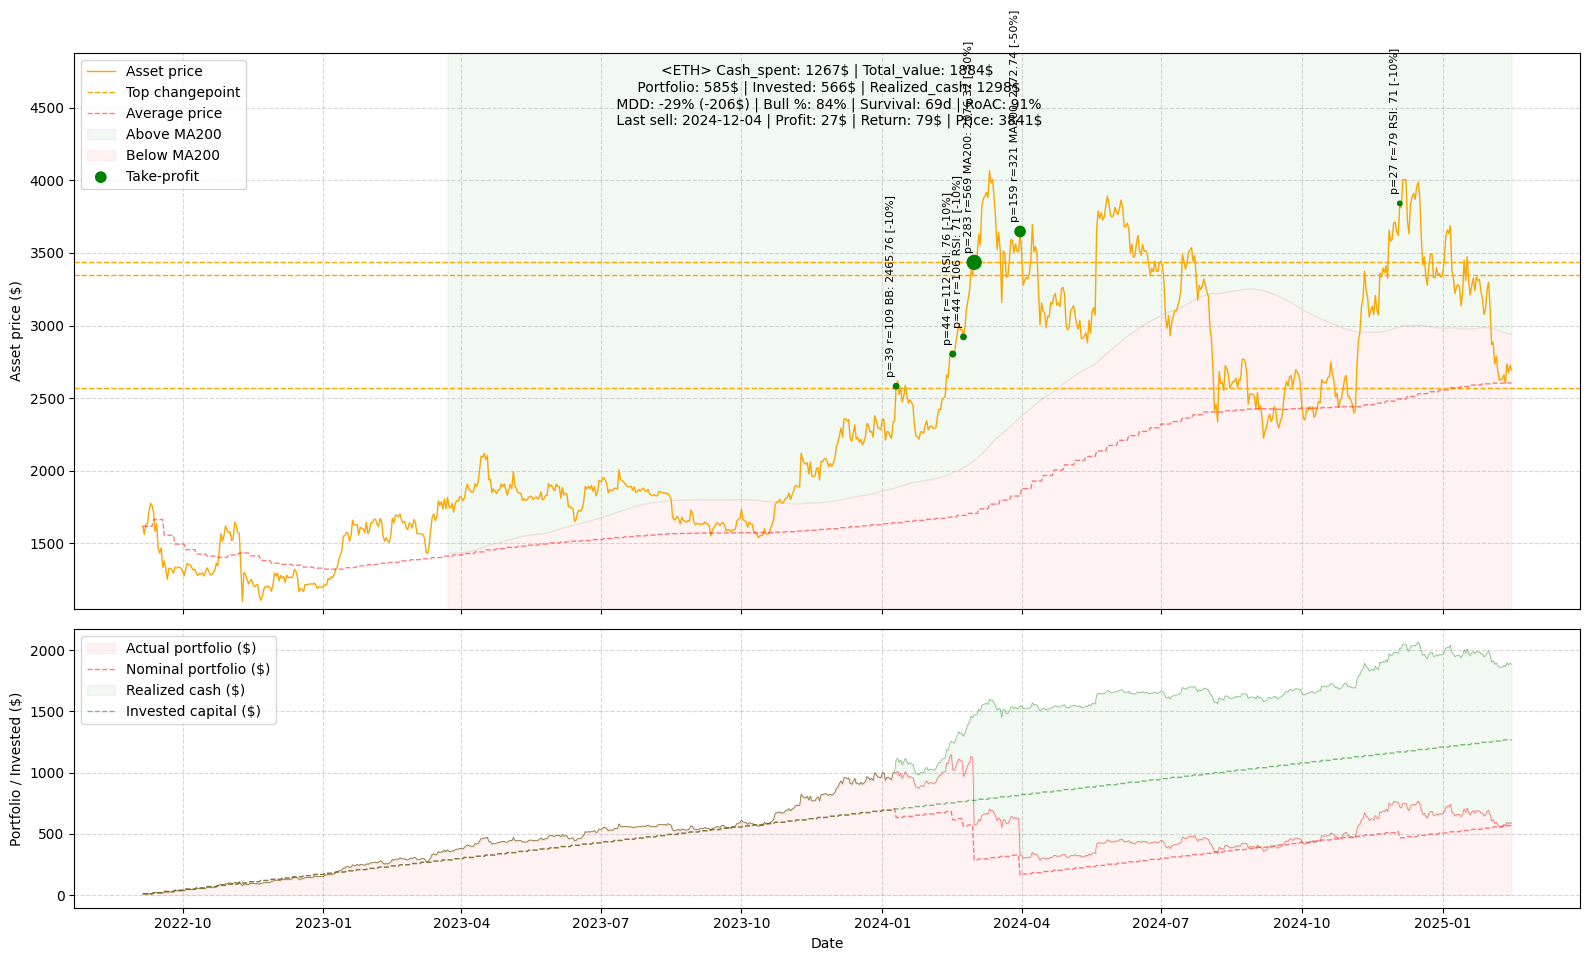

01:04:02 - cmdstanpy - INFO - Chain [1] start processing
01:04:02 - cmdstanpy - INFO - Chain [1] done processing


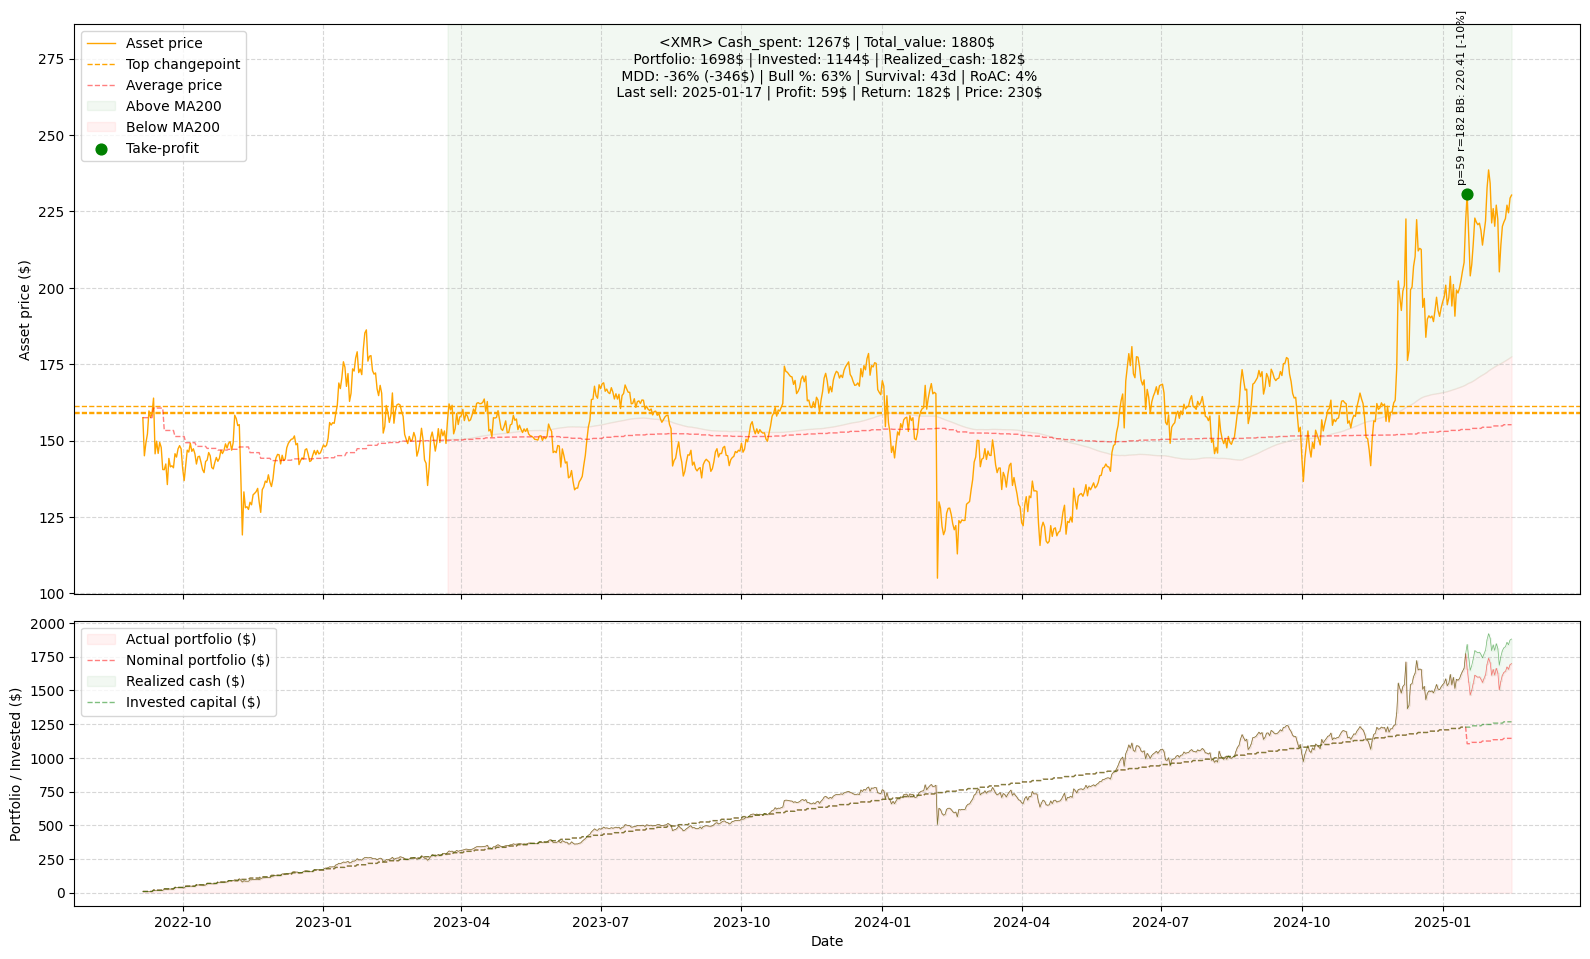

01:04:02 - cmdstanpy - INFO - Chain [1] start processing
01:04:03 - cmdstanpy - INFO - Chain [1] done processing


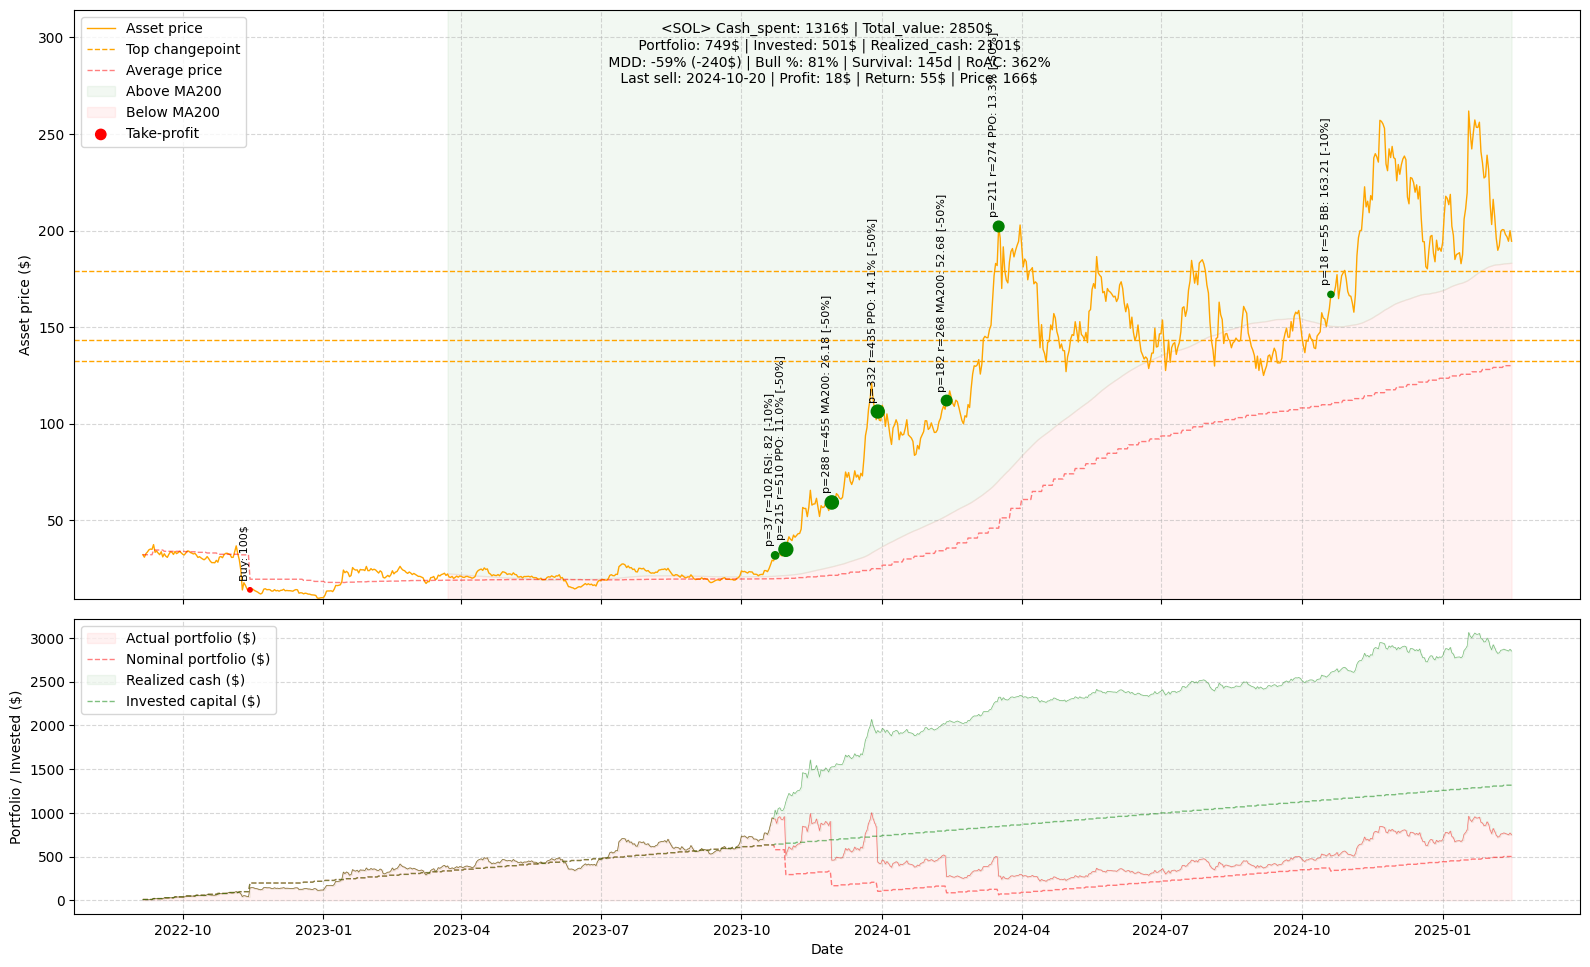

01:04:03 - cmdstanpy - INFO - Chain [1] start processing
01:04:03 - cmdstanpy - INFO - Chain [1] done processing


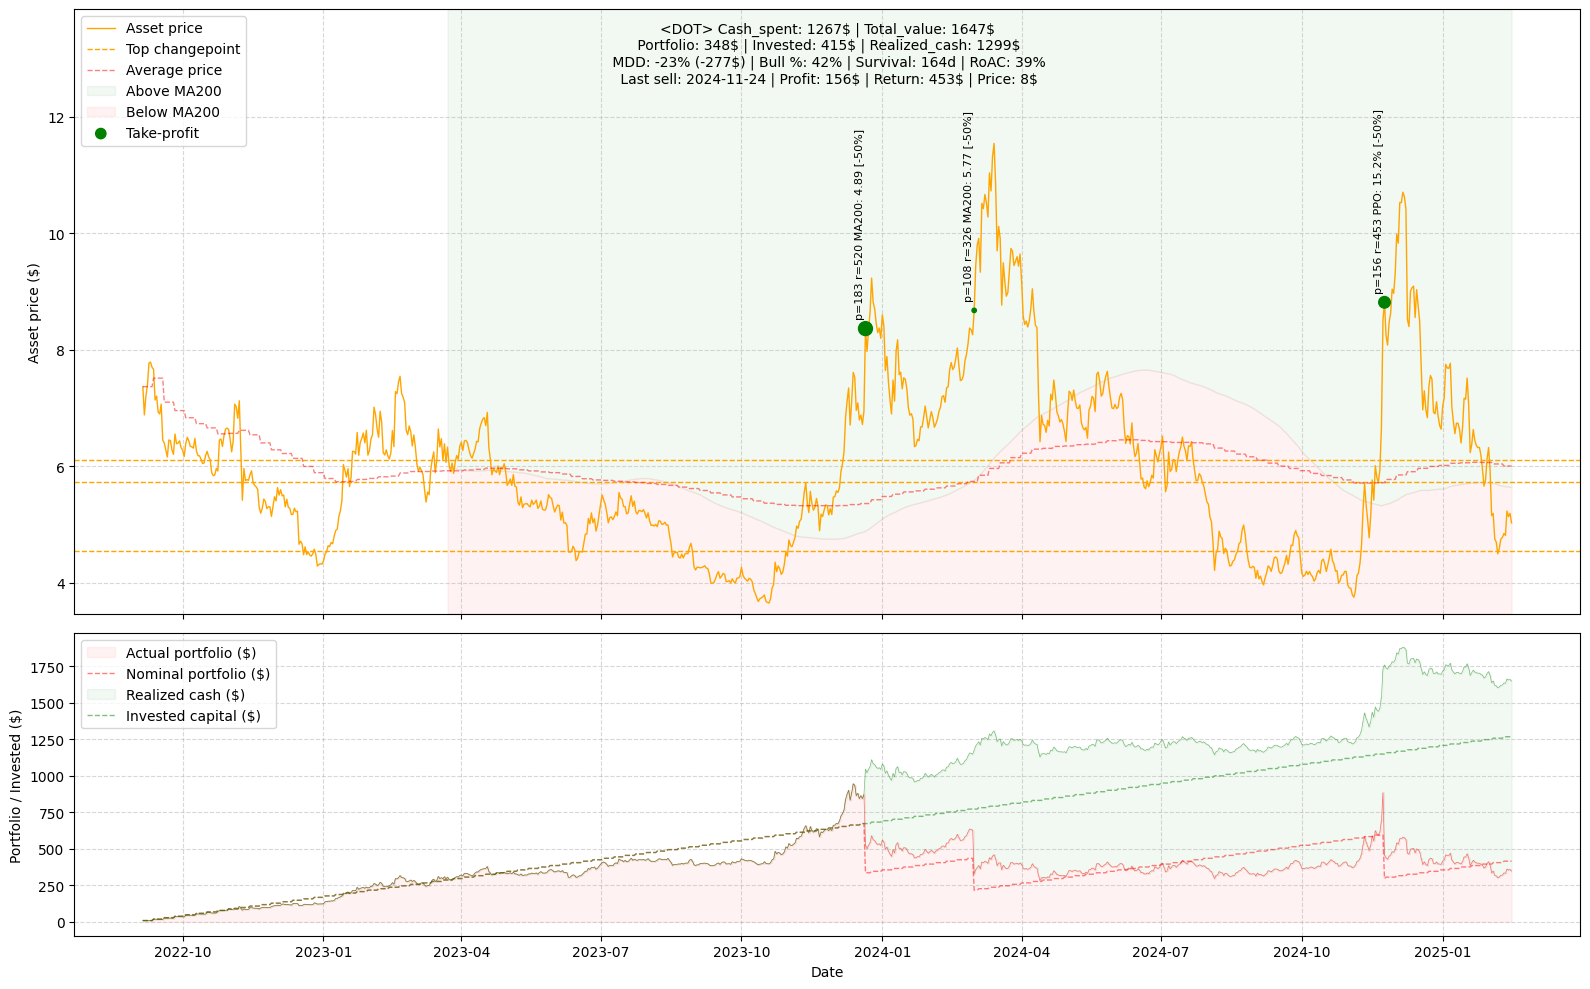

01:04:03 - cmdstanpy - INFO - Chain [1] start processing
01:04:03 - cmdstanpy - INFO - Chain [1] done processing


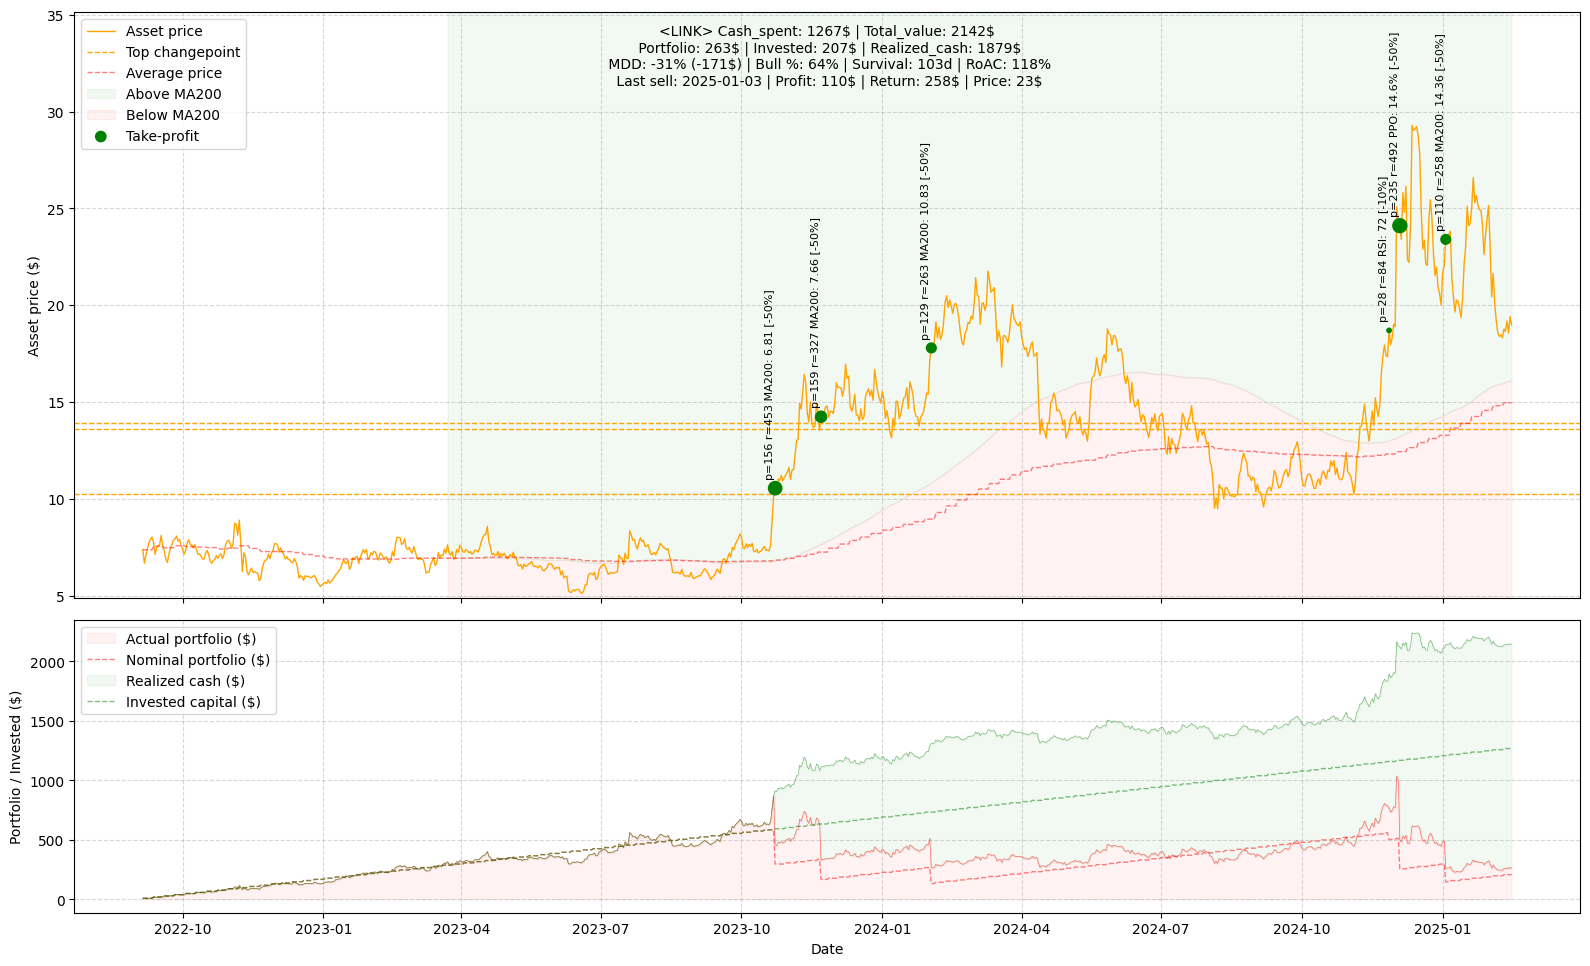

01:04:04 - cmdstanpy - INFO - Chain [1] start processing
01:04:04 - cmdstanpy - INFO - Chain [1] done processing


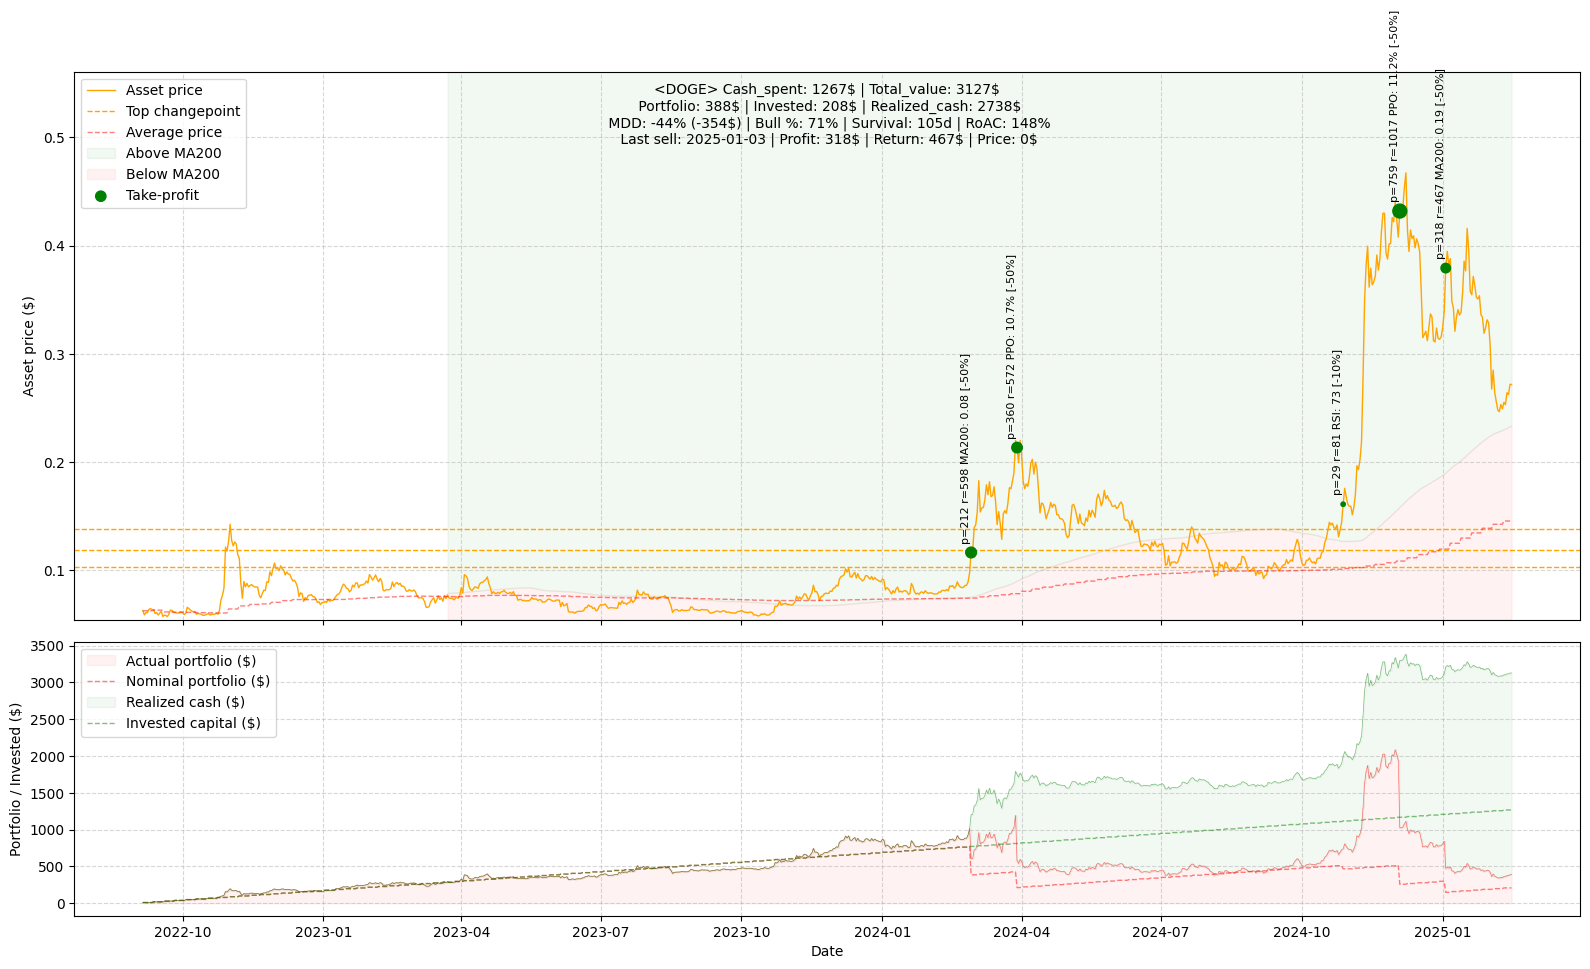

01:04:04 - cmdstanpy - INFO - Chain [1] start processing
01:04:04 - cmdstanpy - INFO - Chain [1] done processing


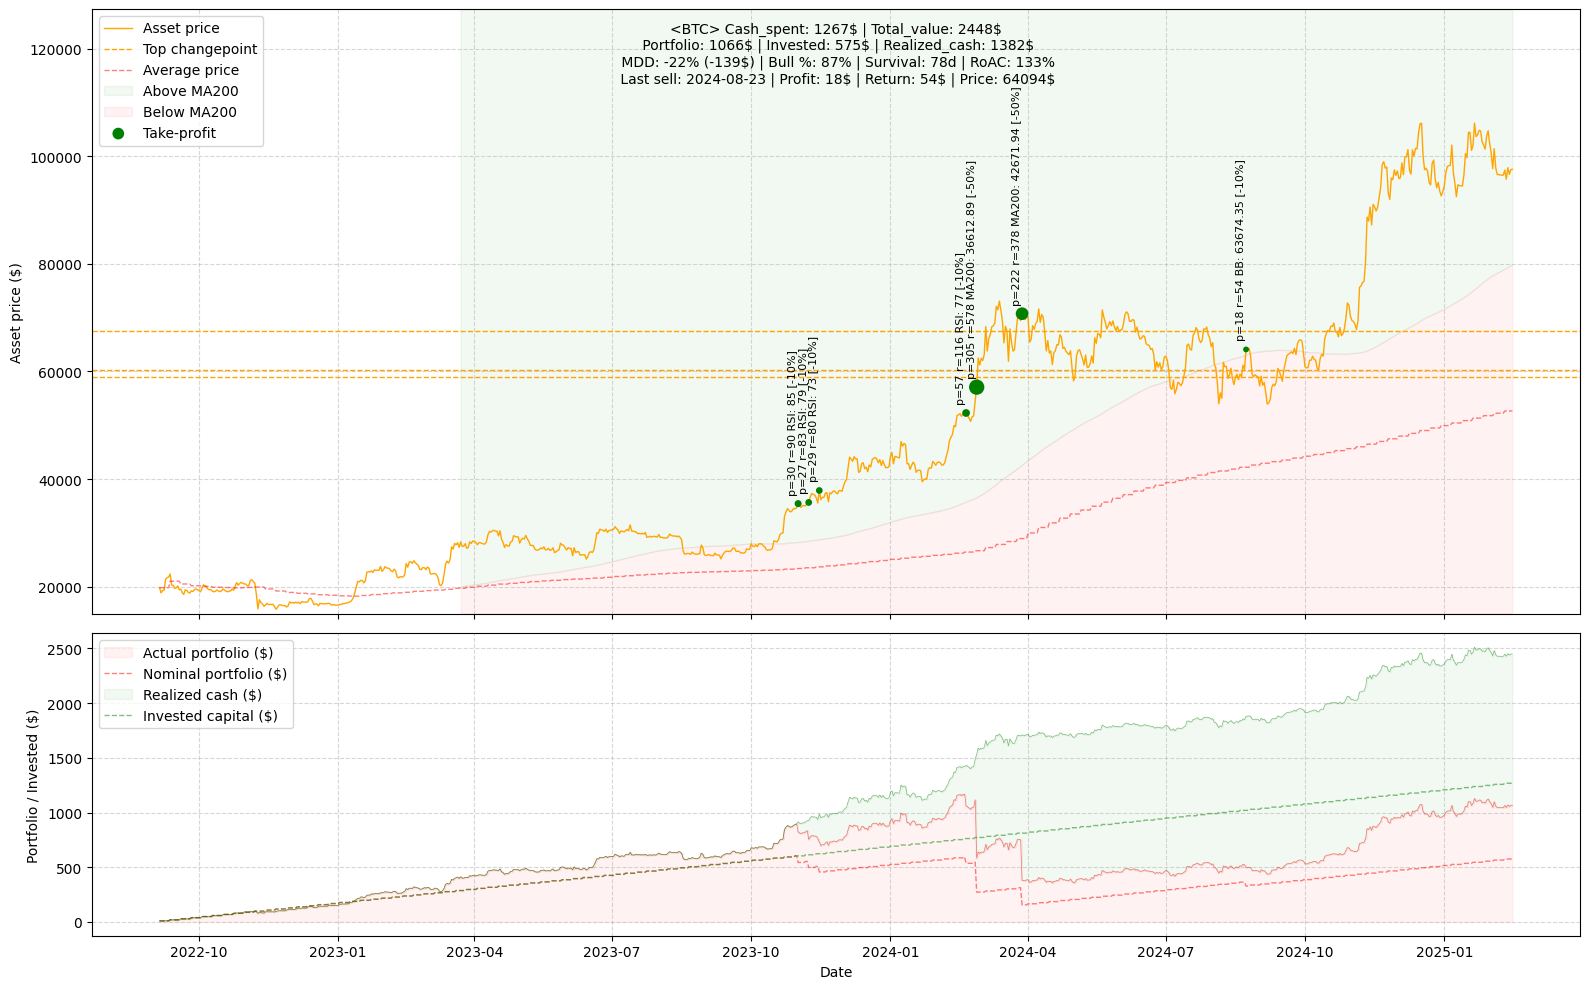

01:04:05 - cmdstanpy - INFO - Chain [1] start processing
01:04:05 - cmdstanpy - INFO - Chain [1] done processing


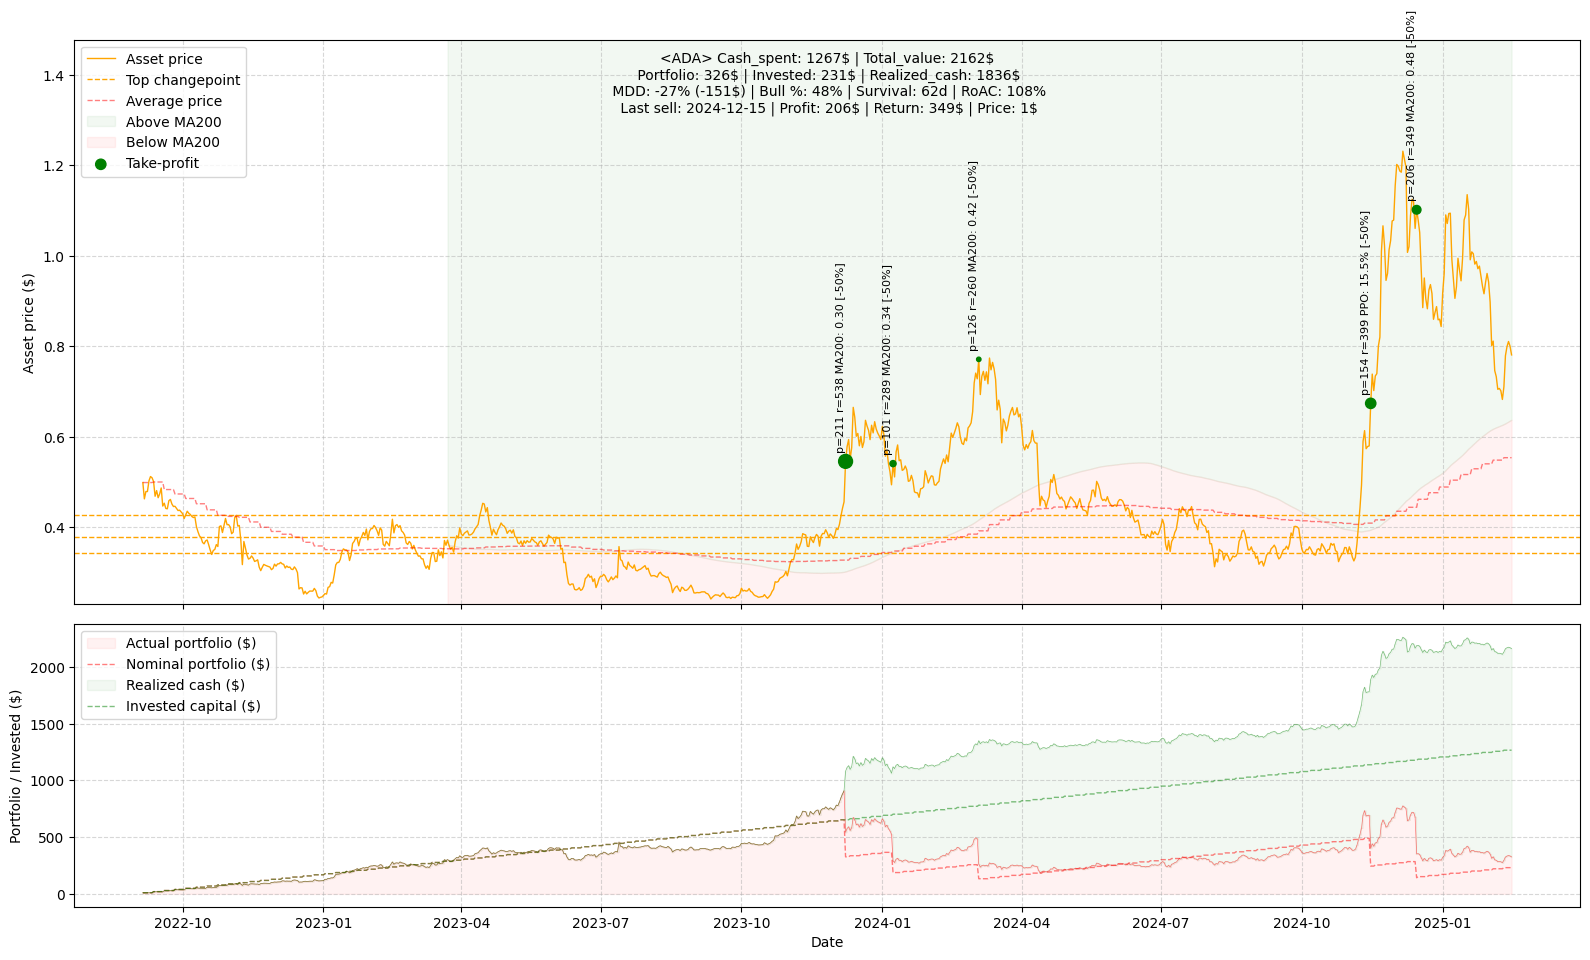

01:04:05 - cmdstanpy - INFO - Chain [1] start processing
01:04:05 - cmdstanpy - INFO - Chain [1] done processing


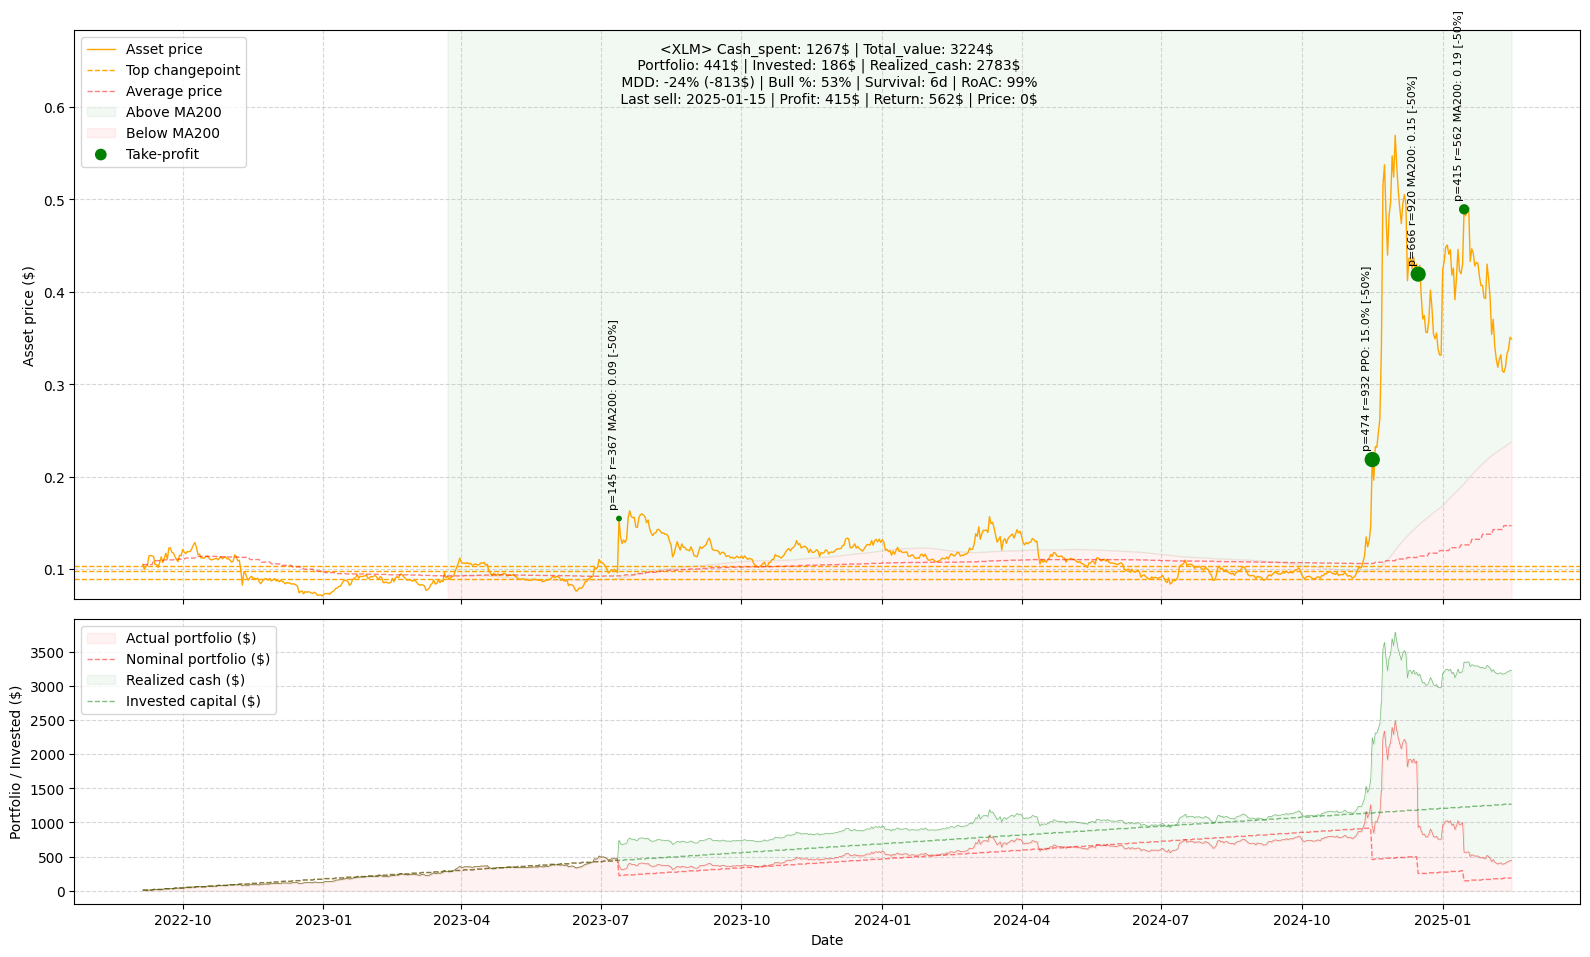

Total invested: $12719.00
Total return: $18678.00
Total value: $24877.00


In [7]:
total_invested = 0
total_profit = 0
total_return = 0
total_value = 0

for stock in random_token:
    stock_prices = prices[stock]
    stock_prices = stock_prices.dropna()

    stock_prices = stock_prices.iloc[200:]

    try:
        bt = BacktestDCA(
        target=stock,
        prices=stock_prices,
        strategy=strategy
        )
        result, metrics = bt.run()
        ploter(metrics=metrics, history=result)
    except Exception as e:
        print(f"Error backtesting {stock}: {e}")
        continue

    total_invested += metrics['Cash_spent']
    total_return += metrics['Realized_cash']
    total_value += metrics['Total_value']

print(f"Total invested: ${total_invested:.2f}")
print(f"Total return: ${total_return:.2f}")
print(f"Total value: ${total_value:.2f}")

In [8]:
result

,Price,Portfolio_qty,Cost_basis,Cash_spent,Profit,Returns,Realized_cash,Trigger_msg,Portfolio,Average_price,Total_value
Date,,,,,,,,,,,
2022-09-05,0.105038,94.251602,9.90000,9.9,0.0,0.0,0.000000,,9.900000,0.105038,9.900000
2022-09-06,0.099963,94.251602,9.90000,9.9,0.0,0.0,0.000000,,9.421673,0.105038,9.421673
2022-09-07,0.102994,94.251602,9.90000,9.9,0.0,0.0,0.000000,,9.707350,0.105038,9.707350
2022-09-08,0.104370,94.251602,9.90000,9.9,0.0,0.0,0.000000,,9.837040,0.105038,9.837040
2022-09-09,0.114394,94.251602,9.90000,9.9,0.0,0.0,0.000000,,10.781818,0.105038,10.781818
...,...,...,...,...,...,...,...,...,...,...,...
2025-02-11,0.318414,1265.262060,186.24375,1267.2,0.0,0.0,2783.069828,,402.877157,0.147198,3185.946985
2025-02-12,0.332971,1265.262060,186.24375,1267.2,0.0,0.0,2783.069828,,421.295582,0.147198,3204.365410
2025-02-13,0.337619,1265.262060,186.24375,1267.2,0.0,0.0,2783.069828,,427.176520,0.147198,3210.246348


In [9]:
(result['Portfolio'] > 0).sum()

np.int64(895)

In [10]:
metrics

{'Target': 'XLM',
 'Cash_spent': 1267,
 'Realized_cash': 2783,
 'Portfolio': 441,
 'Invested': 186,
 'Total_value': 3224,
 'Bull_history': 53,
 'Avg_price': np.float64(0.14719776712767768),
 'Num_take_profits': 4,
 'MDD': -24,
 'MDD_usd': -813,
 'MA200_survival_days': 6.0,
 'RoAC': 99}